# 02_sarima.ipynb — SARIMA Modeling & Diagnostics

**UAS ADW** — Perbandingan SARIMA vs Tree-Based ML (Random Forest & XGBoost)

Tujuan: Identifikasi orde SARIMA optimal, fitting, diagnostik residual, forecasting rolling origin (h=1,7,30), dan uji BDS pada residual.

In [1]:
# ==============================================================================
# SETUP & IMPORTS
# ==============================================================================
import os
import warnings
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import product
from datetime import date

from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.stats.stattools import jarque_bera
from scipy.stats import norm

warnings.filterwarnings("ignore")

DATA_DIR = "../data"
OUTPUT_DIR = os.path.join(DATA_DIR, "sarima_output")
FIGURES_DIR = os.path.join(DATA_DIR, "figures")
os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)

print(f"DATA_DIR: {DATA_DIR}")
print(f"OUTPUT_DIR: {OUTPUT_DIR}")
print(f"FIGURES_DIR: {FIGURES_DIR}")

DATA_DIR: ../data
OUTPUT_DIR: ../data/sarima_output
FIGURES_DIR: ../data/figures


In [2]:
# ==============================================================================
# LOAD DATA
# ==============================================================================
df = pd.read_csv(os.path.join(DATA_DIR, "seri_harian.csv"), parse_dates=["tanggal"])
df.set_index("tanggal", inplace=True)
df = df.asfreq("D")

komoditas = ["cabe_rawit", "bawang_merah", "beras_premium"]
print(f"Data: {len(df)} hari | Komoditas: {komoditas}")
print(f"Range: {df.index.min()} s/d {df.index.max()}")
print(df.head())
print(df.tail())

Data: 1339 hari | Komoditas: ['cabe_rawit', 'bawang_merah', 'beras_premium']
Range: 2023-01-01 00:00:00 s/d 2026-08-31 00:00:00
              cabe_rawit  bawang_merah  beras_premium
tanggal                                              
2023-01-01  47857.142857  31857.142857   12471.428571
2023-01-02  61428.571429  32571.428571   12471.428571
2023-01-03  64285.714286  32571.428571   12471.428571
2023-01-04  65000.000000  32714.285714   12471.428571
2023-01-05  57857.142857  32571.428571   12471.428571
              cabe_rawit  bawang_merah  beras_premium
tanggal                                              
2026-08-27  54285.714286  29000.000000   16142.857143
2026-08-28  55714.285714  29428.571429   16428.571429
2026-08-29  55000.000000  29142.857143   16285.714286
2026-08-30  55714.285714  29142.857143   16285.714286
2026-08-31  55428.571429  30000.000000   16428.571429


Grafik tersimpan: ../data/figures/03_acf_pacf_sarima.png


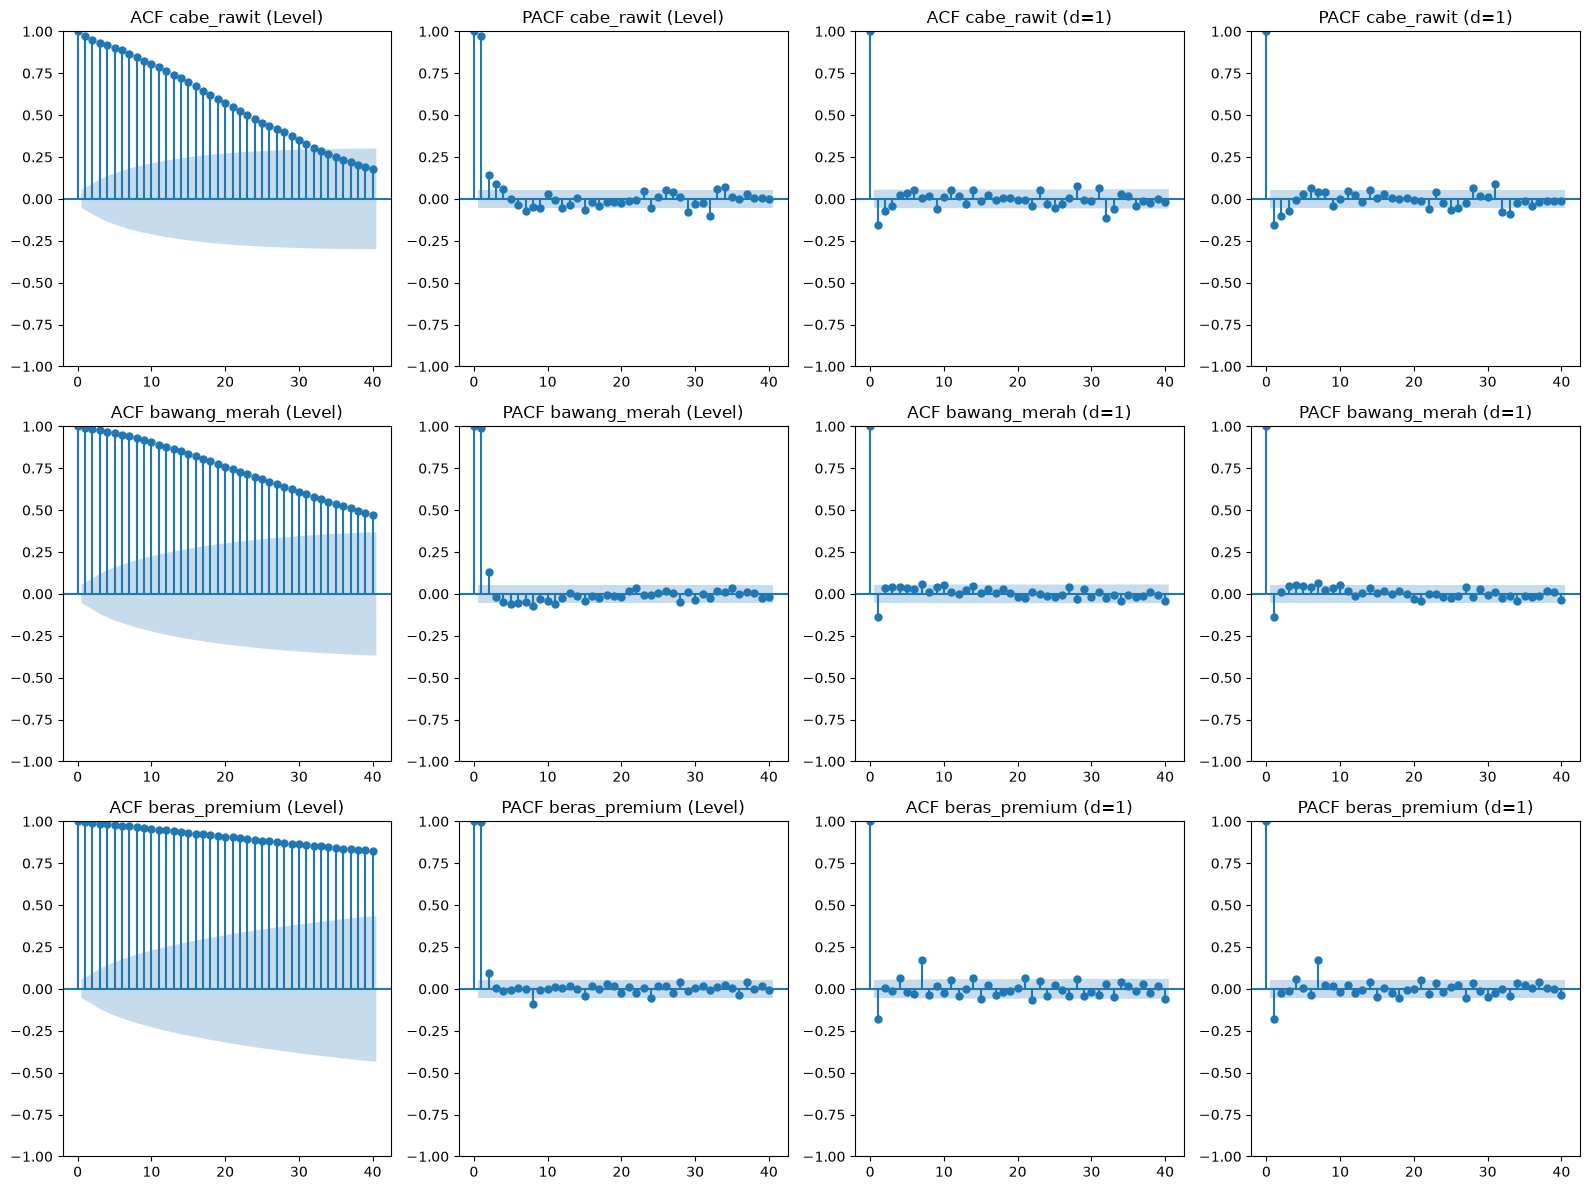

In [3]:
# ==============================================================================
# ACF & PACF PLOTS (Level & First Difference)
# ==============================================================================
fig, axes = plt.subplots(3, 4, figsize=(16, 12))
for i, col in enumerate(komoditas):
    # Level
    plot_acf(df[col].dropna(), ax=axes[i, 0], lags=40, title=f"ACF {col} (Level)")
    plot_pacf(df[col].dropna(), ax=axes[i, 1], lags=40, title=f"PACF {col} (Level)", method="ywm")
    
    # First Difference
    diff = df[col].diff().dropna()
    plot_acf(diff, ax=axes[i, 2], lags=40, title=f"ACF {col} (d=1)")
    plot_pacf(diff, ax=axes[i, 3], lags=40, title=f"PACF {col} (d=1)", method="ywm")

plt.tight_layout()
fig_path = os.path.join(FIGURES_DIR, "03_acf_pacf_sarima.png")
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
print(f"Grafik tersimpan: {fig_path}")
plt.show()

In [4]:
# ==============================================================================
# GRID SEARCH SARIMA ORDER via AIC/BIC
# ==============================================================================

def grid_search_sarima(series, p_range, d_range, q_range, P_range, D_range, Q_range, m=7):
    """
    Grid search SARIMA orders.
    Returns DataFrame with columns: p,d,q,P,D,Q,AIC,BIC,HQIC
    """
    results = []
    for p, d, q in product(p_range, d_range, q_range):
        for P, D, Q in product(P_range, D_range, Q_range):
            try:
                model = SARIMAX(
                    series,
                    order=(p, d, q),
                    seasonal_order=(P, D, Q, m),
                    enforce_stationarity=False,
                    enforce_invertibility=False
                )
                fit = model.fit(disp=False, method="lbfgs", maxiter=200)
                results.append({
                    "p": p, "d": d, "q": q,
                    "P": P, "D": D, "Q": Q,
                    "AIC": fit.aic,
                    "BIC": fit.bic,
                    "HQIC": fit.hqic
                })
            except Exception as e:
                continue
    return pd.DataFrame(results).sort_values("AIC").reset_index(drop=True)

# Search space (relatif kecil untuk komputasi cepat; perluas jika perlu)
p_range = range(0, 4)
d_range = [1]  # dari ADF/KPSS di EDA: d=1
q_range = range(0, 4)
P_range = range(0, 3)
D_range = [1]  # seasonal diff m=7
Q_range = range(0, 3)

best_orders = {}
all_results = {}

for col in komoditas:
    print(f"\n=== Grid search {col} ===")
    res = grid_search_sarima(df[col].dropna(), p_range, d_range, q_range, P_range, D_range, Q_range)
    all_results[col] = res
    if len(res):
        best = res.iloc[0]
        best_orders[col] = (int(best.p), int(best.d), int(best.q), int(best.P), int(best.D), int(best.Q))
        print(f"  Best AIC: {best_orders[col]} | AIC={best.AIC:.2f} | BIC={best.BIC:.2f}")
        print(res.head(5).to_string(index=False))
    else:
        print("  Tidak ada model yang konvergen")
        best_orders[col] = (1, 1, 1, 0, 1, 1)  # fallback

# Simpan hasil grid search
for col, res in all_results.items():
    res.to_csv(os.path.join(OUTPUT_DIR, f"grid_search_{col}.csv"), index=False)

print("\n=== Best Orders Summary ===")
for col, ord in best_orders.items():
    print(f"  {col}: {ord}")


=== Grid search cabe_rawit ===
  Best AIC: (3, 1, 1, 2, 1, 2) | AIC=25947.41 | BIC=25994.04
 p  d  q  P  D  Q          AIC          BIC         HQIC
 3  1  1  2  1  2 25947.409871 25994.037352 25964.895344
 2  1  1  1  1  2 25967.303112 26003.574255 25980.904407
 2  1  1  0  1  2 26033.660941 26064.750493 26045.319194
 1  1  0  2  1  1 26059.099253 26085.011013 26068.815522
 2  1  3  2  1  2 26088.754039 26140.554738 26108.180221

=== Grid search bawang_merah ===
  Best AIC: (3, 1, 3, 1, 1, 2) | AIC=21901.48 | BIC=21953.28
 p  d  q  P  D  Q          AIC          BIC         HQIC
 3  1  3  1  1  2 21901.480306 21953.281005 21920.906488
 1  1  3  2  1  2 21902.187870 21948.808499 21919.671434
 0  1  3  1  1  2 21906.793487 21943.053976 21920.391815
 0  1  3  2  1  2 21907.922403 21949.362962 21923.463349
 3  1  3  0  1  2 21910.788806 21957.409435 21928.272370

=== Grid search beras_premium ===
  Best AIC: (3, 1, 3, 0, 1, 2) | AIC=14964.09 | BIC=15010.71
 p  d  q  P  D  Q          AIC  

In [6]:
# ==============================================================================
# FIT BEST MODELS & RESIDUAL DIAGNOSTICS (Full Data)
# ==============================================================================

fitted_models = {}
diagnostics = []

for col in komoditas:
    print(f"\n=== {col} ===")
    p, d, q, P, D, Q = best_orders[col]
    
    model = SARIMAX(
        df[col],
        order=(p, d, q),
        seasonal_order=(P, D, Q, 7),
        enforce_stationarity=False,
        enforce_invertibility=False
    )
    fit = model.fit(disp=False, method="lbfgs", maxiter=500)
    fitted_models[col] = fit
    
    print(f"  Order: ({p},{d},{q})({P},{D},{Q})7")
    print(f"  AIC: {fit.aic:.2f} | BIC: {fit.bic:.2f} | LogLik: {fit.llf:.2f}")
    
    # Residuals
    resid = fit.resid.dropna()
    
    # Ljung-Box (h=10, 20, 30)
    for h in [10, 20, 30]:
        lb = acorr_ljungbox(resid, lags=[h], return_df=True)
        diagnostics.append({
            "komoditas": col,
            "uji": f"Ljung-Box(h={h})",
            "statistic": lb["lb_stat"].iloc[0],
            "p_value": lb["lb_pvalue"].iloc[0],
            "lolos": lb["lb_pvalue"].iloc[0] > 0.05
        })
    
    # Jarque-Bera
    jb_stat, jb_p, _, _ = jarque_bera(resid)
    diagnostics.append({
        "komoditas": col,
        "uji": "Jarque-Bera",
        "statistic": jb_stat,
        "p_value": jb_p,
        "lolos": jb_p > 0.05
    })
    
    # ARCH-LM
    arch_stat, arch_p, _, _ = het_arch(resid, nlags=10)
    diagnostics.append({
        "komoditas": col,
        "uji": "ARCH-LM(10)",
        "statistic": arch_stat,
        "p_value": arch_p,
        "lolos": arch_p > 0.05  
    })
    
    # Summary print
    for d in diagnostics[-5:]:
        print(f"  {d['uji']:15s} stat={d['statistic']:.4f} p={d['p_value']:.4f} {'✓' if d['lolos'] else '✗'}")


=== cabe_rawit ===
  Order: (3,1,1)(2,1,2)7
  AIC: 25947.41 | BIC: 25994.04 | LogLik: -12964.70
  Ljung-Box(h=10) stat=19.1130 p=0.0389 ✗
  Ljung-Box(h=20) stat=26.5484 p=0.1485 ✓
  Ljung-Box(h=30) stat=39.6438 p=0.1120 ✓
  Jarque-Bera     stat=174411.4170 p=0.0000 ✗
  ARCH-LM(10)     stat=205.3522 p=0.0000 ✗

=== bawang_merah ===
  Order: (3,1,3)(1,1,2)7
  AIC: 21901.48 | BIC: 21953.28 | LogLik: -10940.74
  Ljung-Box(h=10) stat=81.5154 p=0.0000 ✗
  Ljung-Box(h=20) stat=91.3847 p=0.0000 ✗
  Ljung-Box(h=30) stat=96.8514 p=0.0000 ✗
  Jarque-Bera     stat=1715315.6665 p=0.0000 ✗
  ARCH-LM(10)     stat=389.0470 p=0.0000 ✗

=== beras_premium ===
  Order: (3,1,3)(0,1,2)7
  AIC: 14964.09 | BIC: 15010.71 | LogLik: -7473.05
  Ljung-Box(h=10) stat=755.4506 p=0.0000 ✗
  Ljung-Box(h=20) stat=755.5482 p=0.0000 ✗
  Ljung-Box(h=30) stat=755.7417 p=0.0000 ✗
  Jarque-Bera     stat=8002308.3326 p=0.0000 ✗
  ARCH-LM(10)     stat=28.4098 p=0.0016 ✗


Grafik tersimpan: ../data/figures/04_residual_diagnostics.png


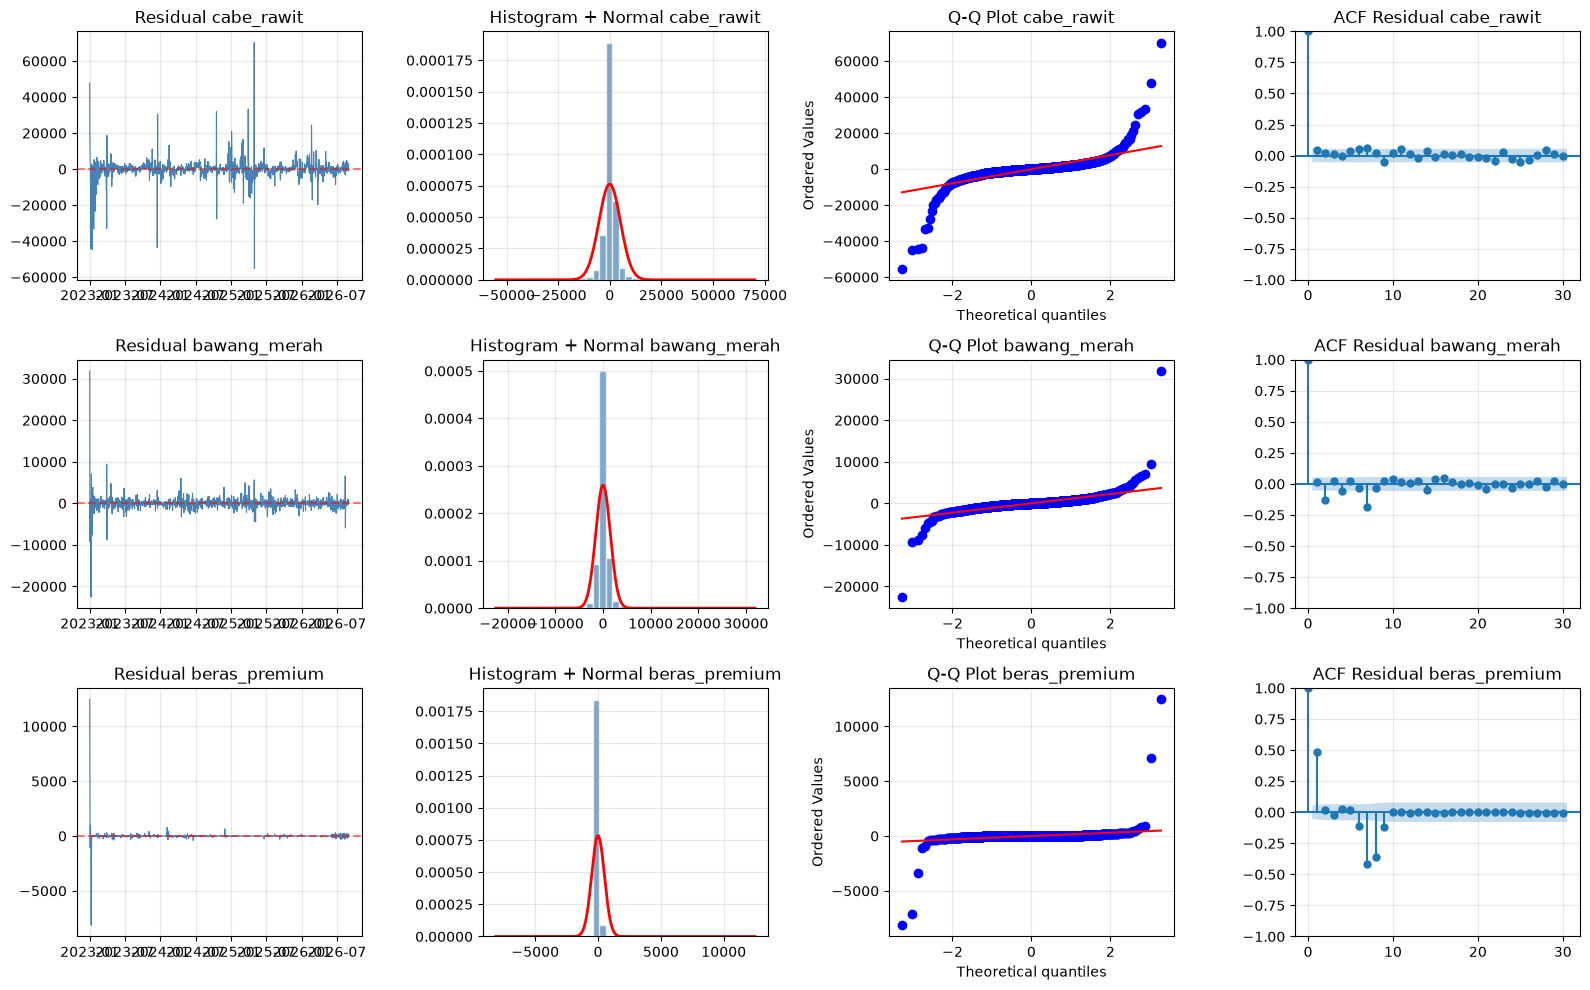

In [7]:
# ==============================================================================
# RESIDUAL DIAGNOSTIC PLOTS
# ==============================================================================

fig, axes = plt.subplots(3, 4, figsize=(16, 10))

for i, col in enumerate(komoditas):
    fit = fitted_models[col]
    resid = fit.resid.dropna()
    
    # Residual time series
    axes[i, 0].plot(resid.index, resid.values, color='steelblue', linewidth=0.8)
    axes[i, 0].axhline(0, color='red', linestyle='--', alpha=0.5)
    axes[i, 0].set_title(f"Residual {col}")
    axes[i, 0].grid(True, alpha=0.3)
    
    # Histogram + Normal
    axes[i, 1].hist(resid, bins=40, density=True, alpha=0.7, color='steelblue', edgecolor='white')
    x = np.linspace(resid.min(), resid.max(), 200)
    axes[i, 1].plot(x, norm.pdf(x, resid.mean(), resid.std()), 'r-', lw=2)
    axes[i, 1].set_title(f"Histogram + Normal {col}")
    axes[i, 1].grid(True, alpha=0.3)
    
    # Q-Q Plot
    from scipy.stats import probplot
    probplot(resid, dist="norm", plot=axes[i, 2])
    axes[i, 2].set_title(f"Q-Q Plot {col}")
    axes[i, 2].grid(True, alpha=0.3)
    
    # ACF Residual
    plot_acf(resid, ax=axes[i, 3], lags=30, title=f"ACF Residual {col}")
    axes[i, 3].grid(True, alpha=0.3)

plt.tight_layout()
fig_path = os.path.join(FIGURES_DIR, "04_residual_diagnostics.png")
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
print(f"Grafik tersimpan: {fig_path}")
plt.show()

In [8]:
# ==============================================================================
# BDS TEST ON RESIDUALS (Justifikasi Non-linearitas -> ML)
# ==============================================================================

def bds_test(series, eps=None, max_m=5):
    """
    Brock-Dechert-Scheinkman (BDS) test for i.i.d.
    H0: series is i.i.d. (independent and identically distributed)
    H1: series has nonlinear dependence

    Returns dict with statistics per embedding dimension m.
    Implementation based on Brock et al. (1987).
    """
    from scipy.spatial.distance import pdist
    
    x = np.asarray(series).ravel()
    n = len(x)
    
    if eps is None:
        eps = 0.5 * np.std(x)  # common choice: 0.5-2.0 * std
    
    results = {}
    for m in range(2, max_m + 1):
        # Create m-history vectors
        vectors = np.column_stack([x[i:n-m+1+i] for i in range(m)])
        
        # Correlation integral C_m(eps)
        if len(vectors) > 2000:
            idx = np.random.choice(len(vectors), 2000, replace=False)
            vectors = vectors[idx]
        
        dists = pdist(vectors, metric='chebyshev')
        Cm = np.mean(dists < eps)
        
        dists1 = pdist(x.reshape(-1, 1), metric='chebyshev')
        C1 = np.mean(dists1 < eps)
        
        C1m = C1 ** m
        if Cm > 0 and C1m > 0:
            sigma2 = 4 * (m**2) * (C1**(2*m - 2)) * C1 * (1 - C1) / n
            if sigma2 > 0:
                W = np.sqrt(n) * (Cm - C1m) / np.sqrt(sigma2)
                p_value = 2 * (1 - norm.cdf(abs(W)))
            else:
                W, p_value = np.nan, np.nan
        else:
            W, p_value = np.nan, np.nan
        
        results[m] = {
            "C_m": Cm,
            "C_1^m": C1m,
            "W_stat": W,
            "p_value": p_value,
            "reject_iid": p_value < 0.05 if not np.isnan(p_value) else None
        }
    
    return results

print("=== BDS Test on SARIMA Residuals ===")
bds_results = {}

for col in komoditas:
    fit = fitted_models[col]
    resid = fit.resid.dropna().values
    print(f"\n{col} (n={len(resid)})")
    
    for eps_mult in [0.5, 1.0, 1.5]:
        eps = eps_mult * np.std(resid)
        res = bds_test(resid, eps=eps, max_m=5)
        bds_results[f"{col}_eps{eps_mult}"] = res
        
        print(f"  eps={eps_mult:.1f}*std ({eps:.2f}):")
        for m, r in res.items():
            reject = r["reject_iid"]
            status = "REJECT H0 (non-iid)" if reject else "FAIL TO REJECT H0 (iid)"
            print(f"    m={m}: W={r['W_stat']:.3f}, p={r['p_value']:.4f} -> {status}")

=== BDS Test on SARIMA Residuals ===

cabe_rawit (n=1339)
  eps=0.5*std (2613.00):
    m=2: W=44.323, p=0.0000 -> REJECT H0 (non-iid)
    m=3: W=82.339, p=0.0000 -> REJECT H0 (non-iid)
    m=4: W=119.116, p=0.0000 -> REJECT H0 (non-iid)
    m=5: W=157.447, p=0.0000 -> REJECT H0 (non-iid)
  eps=1.0*std (5226.00):
    m=2: W=34.020, p=0.0000 -> REJECT H0 (non-iid)
    m=3: W=54.623, p=0.0000 -> REJECT H0 (non-iid)
    m=4: W=70.124, p=0.0000 -> REJECT H0 (non-iid)
    m=5: W=85.423, p=0.0000 -> REJECT H0 (non-iid)
  eps=1.5*std (7839.01):
    m=2: W=25.210, p=0.0000 -> REJECT H0 (non-iid)
    m=3: W=37.067, p=0.0000 -> REJECT H0 (non-iid)
    m=4: W=44.570, p=0.0000 -> REJECT H0 (non-iid)
    m=5: W=51.244, p=0.0000 -> REJECT H0 (non-iid)

bawang_merah (n=1339)
  eps=0.5*std (767.76):
    m=2: W=21.600, p=0.0000 -> REJECT H0 (non-iid)
    m=3: W=37.741, p=0.0000 -> REJECT H0 (non-iid)
    m=4: W=54.174, p=0.0000 -> REJECT H0 (non-iid)
    m=5: W=71.195, p=0.0000 -> REJECT H0 (non-iid)
  

In [9]:
# ==============================================================================
# ROLLING ORIGIN FORECASTING (3 Folds, h=1,7,30) -- OPTIMIZED
# Satu fit per origin (forecast max_h), lalu ambil nilai ke-h.
# Forecast antar-horizon menjadi PAIRED (origin sama) -> siap untuk Diebold-Mariano.
# ==============================================================================
import time

def rolling_origin_forecast(series, order, seasonal_order, test_idx,
                            horizons=(1, 7, 30), log_every=25):
    """
    Rolling origin forecast for a single fold.

    Fit sekali per origin dengan horizon maksimum, lalu ambil prediksi
    untuk tiap horizon dari forecast yang sama. Origin yang dipakai
    identik untuk semua horizon (paired design).

    Returns: {h: {'y_true': [...], 'y_pred': [...], 'dates': [...]}}
    """
    horizons = list(horizons)
    max_h = max(horizons)
    results = {h: {"y_true": [], "y_pred": [], "dates": []} for h in horizons}

    n_origin = len(test_idx) - max_h + 1
    t0 = time.time()

    for i in range(n_origin):
        origin = test_idx[i]
        train_data = series.loc[:origin]
        try:
            model = SARIMAX(
                train_data,
                order=order,
                seasonal_order=seasonal_order,
                enforce_stationarity=False,
                enforce_invertibility=False,
            )
            fit = model.fit(disp=False, method="lbfgs", maxiter=200)
            fc = fit.forecast(max_h)
        except Exception:
            continue

        for h in horizons:
            target_date = test_idx[i + h - 1]
            results[h]["y_true"].append(float(series.loc[target_date]))
            results[h]["y_pred"].append(float(fc.iloc[h - 1]))
            results[h]["dates"].append(target_date)

        if log_every and (i + 1) % log_every == 0:
            el = time.time() - t0
            print(f"    origin {i+1}/{n_origin} | {el:6.1f}s | "
                  f"eta {el/(i+1)*(n_origin-i-1):6.1f}s", flush=True)

    return results


# Define folds
folds = [
    ("Fold1", df.index[(df.index >= "2023-01-01") & (df.index <= "2024-12-31")],
     df.index[(df.index >= "2025-01-01") & (df.index <= "2025-06-30")]),
    ("Fold2", df.index[(df.index >= "2023-01-01") & (df.index <= "2025-06-30")],
     df.index[(df.index >= "2025-07-01") & (df.index <= "2025-12-31")]),
    ("Fold3", df.index[(df.index >= "2023-01-01") & (df.index <= "2025-12-31")],
     df.index[(df.index >= "2026-01-01") & (df.index <= "2026-08-31")]),
]

all_forecasts = []
horizons = [1, 7, 30]
t_start = time.time()

for fold_name, train_idx, test_idx in folds:
    print(f"\n=== {fold_name} === Train: {train_idx[0].date()} to {train_idx[-1].date()} "
          f"| Test: {test_idx[0].date()} to {test_idx[-1].date()}", flush=True)

    for col in komoditas:
        p, d, q, P, D, Q = best_orders[col]
        print(f"  {col} order=({p},{d},{q})({P},{D},{Q})7 ...", flush=True)

        fc = rolling_origin_forecast(
            df[col],
            order=(p, d, q),
            seasonal_order=(P, D, Q, 7),
            test_idx=test_idx,
            horizons=horizons,
        )

        for h in horizons:
            y_true = np.array(fc[h]["y_true"])
            y_pred = np.array(fc[h]["y_pred"])
            n = len(y_true)
            if n == 0:
                print(f"    h={h}: tidak ada prediksi (skip)")
                continue

            mae = np.mean(np.abs(y_true - y_pred))
            rmse = np.sqrt(np.mean((y_true - y_pred) ** 2))
            mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100

            for i in range(n):
                all_forecasts.append({
                    "fold": fold_name,
                    "komoditas": col,
                    "horizon": h,
                    "date": fc[h]["dates"][i],
                    "y_true": y_true[i],
                    "y_pred": y_pred[i],
                    "error": y_true[i] - y_pred[i],
                    "abs_error": abs(y_true[i] - y_pred[i]),
                    "squared_error": (y_true[i] - y_pred[i]) ** 2,
                    "mae_fold": mae,
                    "rmse_fold": rmse,
                    "mape_fold": mape,
                    "n_obs": n,
                })
            print(f"    h={h:2d}: n={n:3d} MAE={mae:9.2f} RMSE={rmse:9.2f} MAPE={mape:6.2f}%", flush=True)

elapsed = time.time() - t_start
forecast_df = pd.DataFrame(all_forecasts)
forecast_df.to_csv(os.path.join(OUTPUT_DIR, "sarima_forecast_all.csv"), index=False)

print(f"\nTotal forecast points: {len(forecast_df)} | elapsed: {elapsed/60:.1f} menit")
print(forecast_df.groupby(["fold", "komoditas", "horizon"]).size().unstack(fill_value=0))



=== Fold1 === Train: 2023-01-01 to 2024-12-31 | Test: 2025-01-01 to 2025-06-30
  cabe_rawit order=(3,1,1)(2,1,2)7 ...
    origin 25/152 |  116.2s | eta  590.3s
    origin 50/152 |  187.3s | eta  382.2s
    origin 75/152 |  283.4s | eta  290.9s
    origin 100/152 |  367.3s | eta  191.0s
    origin 125/152 |  429.0s | eta   92.7s
    origin 150/152 |  481.1s | eta    6.4s
    h= 1: n=152 MAE=  2351.90 RMSE=  3435.89 MAPE=  5.36%
    h= 7: n=152 MAE= 11245.34 RMSE= 15530.31 MAPE= 20.44%
    h=30: n=152 MAE= 32040.77 RMSE= 38473.01 MAPE= 75.03%
  bawang_merah order=(3,1,3)(1,1,2)7 ...
    origin 25/152 |  276.6s | eta 1405.0s
    origin 50/152 |  608.4s | eta 1241.2s
    origin 75/152 | 1024.9s | eta 1052.2s
    origin 100/152 | 1450.0s | eta  754.0s
    origin 125/152 | 1814.4s | eta  391.9s
    origin 150/152 | 2279.3s | eta   30.4s
    h= 1: n=152 MAE=   196.65 RMSE=   250.19 MAPE=  0.57%
    h= 7: n=152 MAE=  2050.60 RMSE=  2663.76 MAPE=  5.82%
    h=30: n=152 MAE=  7010.60 RMSE=  816

In [10]:
# ==============================================================================
# METRICS SUMMARY TABLE
# ==============================================================================

metrics_summary = forecast_df.groupby(['komoditas', 'horizon']).agg(
    MAE=('abs_error', 'mean'),
    RMSE=('squared_error', lambda x: np.sqrt(x.mean())),
    MAPE=('error', lambda x: np.mean(np.abs(x / forecast_df.loc[x.index, 'y_true'])) * 100),
    N=('error', 'count')
).reset_index()

print("=== SARIMA Metrics (pooled across folds) ===")
print(metrics_summary.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

metrics_summary.to_csv(os.path.join(OUTPUT_DIR, "sarima_metrics_summary.csv"), index=False)

fold_metrics = forecast_df.groupby(['fold', 'komoditas', 'horizon']).agg(
    MAE=('abs_error', 'mean'),
    RMSE=('squared_error', lambda x: np.sqrt(x.mean())),
    MAPE=('error', lambda x: np.mean(np.abs(x / forecast_df.loc[x.index, 'y_true'])) * 100),
    N=('error', 'count')
).reset_index()

fold_metrics.to_csv(os.path.join(OUTPUT_DIR, "sarima_metrics_per_fold.csv"), index=False)
print("\n=== Per-Fold Metrics ===")
print(fold_metrics.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

=== SARIMA Metrics (pooled across folds) ===
    komoditas  horizon        MAE       RMSE    MAPE   N
 bawang_merah        1   152.1424   204.1711  0.4129 521
 bawang_merah        7  1823.6444  2450.2828  4.8041 521
 bawang_merah       30  5962.5122  7483.7333 16.1578 521
beras_premium        1     6.6769    10.0120  0.0424 521
beras_premium        7    53.9184    88.5225  0.3415 521
beras_premium       30   128.1114   156.2742  0.8141 521
   cabe_rawit        1  1366.3333  2162.3297  3.0190 521
   cabe_rawit        7  7463.0335 11243.3217 14.3725 521
   cabe_rawit       30 23543.3963 29686.7741 51.3636 521

=== Per-Fold Metrics ===
 fold     komoditas  horizon        MAE       RMSE    MAPE   N
Fold1  bawang_merah        1   196.6487   250.1946  0.5734 152
Fold1  bawang_merah        7  2050.5990  2663.7563  5.8187 152
Fold1  bawang_merah       30  7010.5956  8168.7424 19.9593 152
Fold1 beras_premium        1     6.3115     7.8837  0.0405 152
Fold1 beras_premium        7    23.7897    2

Grafik tersimpan: ../data/figures/05_sarima_forecast_vs_actual.png


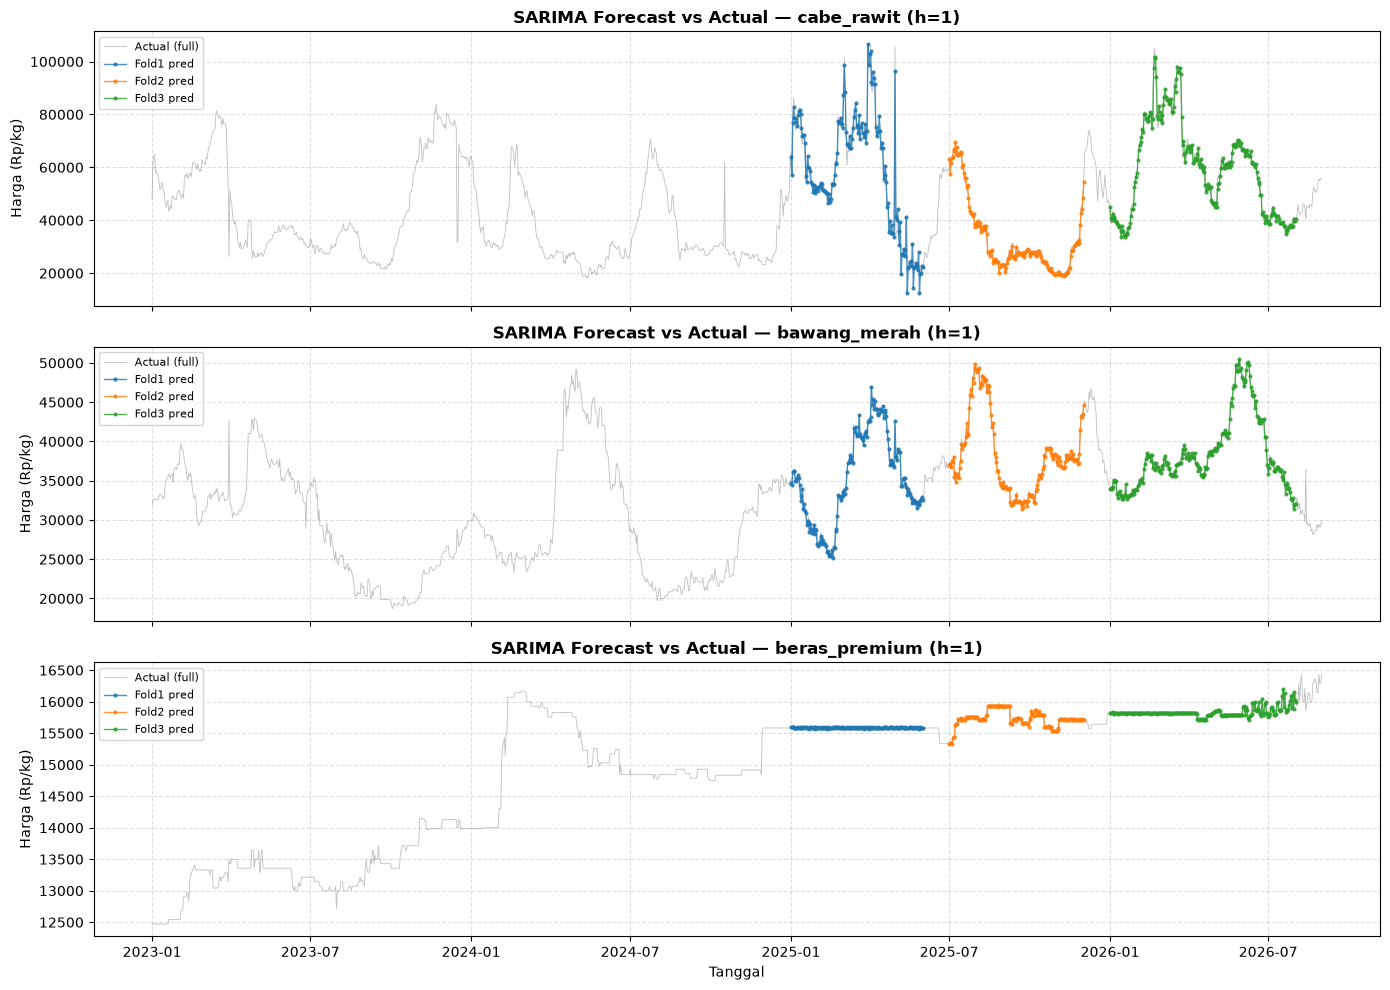

In [11]:
# ==============================================================================
# FORECAST VS ACTUAL PLOTS (per komoditas, h=1)
# ==============================================================================

fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

for i, col in enumerate(komoditas):
    ax = axes[i]
    
    ax.plot(df.index, df[col], color='gray', linewidth=0.6, alpha=0.5, label='Actual (full)')
    
    fc = forecast_df[(forecast_df['komoditas'] == col) & (forecast_df['horizon'] == 1)]
    
    for fold_name in ['Fold1', 'Fold2', 'Fold3']:
        fcf = fc[fc['fold'] == fold_name]
        if len(fcf):
            ax.plot(fcf['date'], fcf['y_pred'], 'o-', markersize=2, linewidth=1,
                   label=f'{fold_name} pred', alpha=0.8)
    
    ax.set_title(f"SARIMA Forecast vs Actual — {col} (h=1)", fontsize=12, fontweight='bold')
    ax.set_ylabel('Harga (Rp/kg)')
    ax.legend(loc='upper left', fontsize=8)
    ax.grid(True, linestyle='--', alpha=0.4)

axes[-1].set_xlabel('Tanggal')
plt.tight_layout()
fig_path = os.path.join(FIGURES_DIR, "05_sarima_forecast_vs_actual.png")
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
print(f"Grafik tersimpan: {fig_path}")
plt.show()

In [12]:
# ==============================================================================
# SAVE FINAL OUTPUTS
# ==============================================================================

orders_df = pd.DataFrame([
    {"komoditas": k, "p": v[0], "d": v[1], "q": v[2],
     "P": v[3], "D": v[4], "Q": v[5], "m": 7}
    for k, v in best_orders.items()
])
orders_df.to_csv(os.path.join(OUTPUT_DIR, "sarima_orders.csv"), index=False)

diag_df = pd.DataFrame(diagnostics)
diag_df.to_csv(os.path.join(OUTPUT_DIR, "sarima_residual_diagnostics.csv"), index=False)

bds_rows = []
for key, res in bds_results.items():
    for m, r in res.items():
        bds_rows.append({
            "komoditas_eps": key,
            "embedding_m": m,
            "C_m": r["C_m"],
            "C_1_pow_m": r["C_1^m"],
            "W_stat": r["W_stat"],
            "p_value": r["p_value"],
            "reject_iid": r["reject_iid"]
        })
bds_df = pd.DataFrame(bds_rows)
bds_df.to_csv(os.path.join(OUTPUT_DIR, "sarima_bds_test.csv"), index=False)

with open(os.path.join(OUTPUT_DIR, "sarima_model_summaries.txt"), "w") as f:
    for col in komoditas:
        f.write(f"{'='*60}\n")
        f.write(f"{col}\n")
        f.write(f"{'='*60}\n")
        f.write(fitted_models[col].summary().as_text())
        f.write(f"\n\n")

print("=== Files Saved ===")
for f in sorted(os.listdir(OUTPUT_DIR)):
    print(f"  {f}")

print("\n=== SARIMA Orders ===")
print(orders_df.to_string(index=False))

=== Files Saved ===
  grid_search_bawang_merah.csv
  grid_search_beras_premium.csv
  grid_search_cabe_rawit.csv
  sarima_bds_test.csv
  sarima_forecast_all.csv
  sarima_metrics_per_fold.csv
  sarima_metrics_summary.csv
  sarima_model_summaries.txt
  sarima_orders.csv
  sarima_residual_diagnostics.csv

=== SARIMA Orders ===
    komoditas  p  d  q  P  D  Q  m
   cabe_rawit  3  1  1  2  1  2  7
 bawang_merah  3  1  3  1  1  2  7
beras_premium  3  1  3  0  1  2  7
